
<h1 align="center"> CSE 242 Assignment 2



<h2 align="center"> 3 Questions, 100 pts
    
    Your name: Ioannis Barous          Student ID: 2252832

## Instruction 

- Submit your assignments onto **Canvas** by the due date. Upload a <code>zip</code> file containing:

    (1) The saved/latest <code>.ipynb</code> file.

    (2) Also save your file into a pdf version, if error appears, save an html version instead (easy to grade for written questions).
    
    (3) All other materials to make your <code>.ipynb</code> file runnable.
    
    **For assignment related questions, please reach TA or grader through EdDiscussion.**
    
- This is an **individual** assignment. All help from others (from the web, books other than text, genAI, or people other than the TA or instructor) must be clearly acknowledged. 
- Most coding parts can be finished with only 1-2 lines of codes.
- Make sure you have installed required packages: <code>scikit-learn</code>.
- Double click to edit each markdown cell.

## Objective 

- **Task 1:** Maximum likelihood estiamtion (math)
- **Task 2:** Linear Regression (with Scikit-learn)
- **Task 3:** Principle Component Analysis (with Scikit-learn)

# Question 1 (Maximum likelihood estiamtion and Posterior, 20 pts) 

Assume we have a coin that has some unknown probability $h$ of coming up heads (and probability $1-h$ of coming up tails). If the coin is flipped five times getting three heads and two tails ($\mathbf{HHHTT}$) then:

(a -- 10pts) What is the maximum likelihood estimate for $h$?

(b -- 10pts) Assume that (before flipping the coin) we have a prior density $p(h)$ for the various values of $h\in [0,1]$. Give the formula for the posterior probability density $p(h \mid \mathbf{HHHTT})$ as a function of the prior $p(h)$.

For Question 1(b), the solution is acceptable if the formula contains an integral.

**Solution (a)**:

The five flips are independent and each one comes up heads with probability $h$ (tails with probability $1-h$). So the likelihood of the observed sequence $\mathbf{HHHTT}$ is

$$L(h) = P(\mathbf{HHHTT} \mid h) = h \cdot h \cdot h \cdot (1-h) \cdot (1-h) = h^3 (1-h)^2, \qquad h \in [0,1].$$

For $0 < h < 1$, take the log-likelihood:

$$\ell(h) = \log L(h) = 3 \log h + 2 \log(1-h).$$

Differentiate and set the derivative to zero:

$$\ell'(h) = \frac{3}{h} - \frac{2}{1-h} = 0 \;\Longrightarrow\; 3(1-h) = 2h \;\Longrightarrow\; 3 = 5h \;\Longrightarrow\; h = \frac{3}{5}.$$

Check that this is a maximum. The second derivative is

$$\ell''(h) = -\frac{3}{h^2} - \frac{2}{(1-h)^2} < 0 \quad \text{for all } h \in (0,1),$$

so $\ell$ is strictly concave on $(0,1)$ and $h = 3/5$ is its unique maximizer there. At the boundary, $L(0) = L(1) = 0$, while $L(3/5) = \left(\tfrac{3}{5}\right)^3 \left(\tfrac{2}{5}\right)^2 = \tfrac{108}{3125} \approx 0.0346 > 0$, so neither endpoint is better. Therefore

$$\boxed{\hat{h}_{\text{MLE}} = \frac{3}{5} = 0.6}$$

**Solution (b)**:

By Bayes' rule, the posterior density is the likelihood times the prior, divided by the probability of the data:

$$p(h \mid \mathbf{HHHTT}) = \frac{P(\mathbf{HHHTT} \mid h)\, p(h)}{P(\mathbf{HHHTT})} = \frac{h^3 (1-h)^2\, p(h)}{\displaystyle\int_0^1 t^3 (1-t)^2\, p(t)\, dt}, \qquad h \in [0,1].$$

The denominator is the evidence (marginal likelihood) of the data. By the law of total probability it averages the likelihood over all possible values of the coin's bias, weighted by the prior:

$$P(\mathbf{HHHTT}) = \int_0^1 P(\mathbf{HHHTT} \mid t)\, p(t)\, dt = \int_0^1 t^3 (1-t)^2\, p(t)\, dt.$$

It does not depend on $h$; it is the normalizing constant that makes the posterior integrate to 1 over $[0,1]$. So the posterior is proportional to $h^3 (1-h)^2\, p(h)$.

Note: if we only recorded that there were 3 heads in 5 flips (ignoring the order), the likelihood would be $\binom{5}{3} h^3 (1-h)^2 = 10\, h^3 (1-h)^2$. The constant $\binom{5}{3}$ appears in both the numerator and the denominator and cancels, so the posterior (and the MLE in part (a)) is the same.

**If you are not familair with Latex, you may attach a figure/screen-shoot and display the code below.**

In [1]:
from IPython.display import Image
# Replace the figure name
# Image(filename='sample.png') 

# Question 2 (Linear Regression, 40 pts)
In this question, you will be using **Scikit-learn** to empirically apply the Linear Regression model. We will adopt an advertisement dataset **Advertising.csv** from Kaggle. 

### Reading data using Pandas

In [2]:
# Read the dataset you will be working on
# The dataframe loaded with pandas is named as data

import pandas as pd
data = pd.read_csv('Advertising.csv', index_col=0)  # Modify your data path accordingly.

# Take a look at the first 5 rows
data.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [3]:
data.shape

(200, 4)

### Features and responses

What are the features?
- **TV:** advertising dollars spent on TV for a single product in a given market (in thousands of dollars)
- **Radio:** advertising dollars spent on Radio
- **Newspaper:** advertising dollars spent on Newspaper

What is the response?
- **Sales:** sales of a single product in a given market (in thousands of items)

What else do we know?
- There are 200 **observations**, and each observation (each row) is a single market.
- **Your main task**: predict the sales of a single product in a given market.
- Since the response variable is continuous, this is a **regression** problem.

### Linear regression

**Pros:** fast, no tuning required, highly interpretable

**Cons:** adopting the linear regression is unlikely to always generate the best predictive accuracy, since Linear Regression presumes a linear relationship between the features and response. This assumption may not always make sense. (But if one can _transform_ the features so that do have a linear relationship, sometimes progress can be made, for example by taking logs.)

**Expression:**

- $y$: the response
- $\beta_0$: the intercept
- $\beta_1$: the coefficient for $x_1$ (the first feature)
- $\beta_i$ is the coefficient for $x_i$ (the ith feature, $i\in \{1, 2, ..., n\}$)

For this regression task:

$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$

The $\beta$ values ($\beta=[\beta_0, \beta_1, \beta_2, \beta_3]$) are called the **model coefficients**. These values are "learned" during the model fitting step using the "least squares" criterion. Then, we can make use of the fitted model to make predictions!

### Prepare the dataset for training use

- Scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- Pandas is built on top of NumPy, and exposes numpy methods. Thus, X can be a pandas DataFrame, y can be a pandas Series!

In [4]:
# Prepare the feature X
X = data[['TV', 'Radio', 'Newspaper']]

# check the type and shape of X
print(type(X))
print(X.shape)

<class 'pandas.core.frame.DataFrame'>
(200, 3)


In [5]:
# Prepare the response Y
y = data['Sales']
# check the type and shape of y
print(type(y))
print(y.shape)

<class 'pandas.core.series.Series'>
(200,)


## Question 2.1 (Split the dataset into train and test parts, 5 pts)

For features $X$ and response $y$, use **sklearn** to perform the the splitting of dataset: $80\%$ for train data, $20\%$ for the test data.

In [6]:
################# Your answer for Question 2.1   #################
from sklearn.model_selection import train_test_split
# Split X and y into 80% train / 20% test;
# random_state=42 fixes the shuffle so Question 2.5 can reuse the same split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

################# Your code above #################

Double check the shape of train and test data:

In [7]:
# default split is 80% for training and 20% for testing
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(160, 3)
(160,)
(40, 3)
(40,)


## Question 2.2 (Train a Linear regression model via Scikit-learn, 10 pts)

Assume you model is named as **model**, and you train the linear regression model to fit on the training data.

In [8]:
################# Your answer for Question 2.2   #################
# Name your linear regression model as 'model', so proceeding cells won't run into errors.
from sklearn.linear_model import LinearRegression
# Create a linear regression model and fit it (least squares) on the training data
model = LinearRegression().fit(X_train, y_train)

################# Your code above #################

In [9]:
# Take a look at your model coefficients
import numpy as np
print(np.round(model.intercept_, 4))
print([np.round(val, 4) for val in model.coef_])

2.9791
[np.float64(0.0447), np.float64(0.1892), np.float64(0.0028)]


In [10]:
# Match the feature names with the trained coefficients
list(zip(data.columns[:3].tolist(), model.coef_))

[('TV', np.float64(0.044729517468716305)),
 ('Radio', np.float64(0.18919505423437652)),
 ('Newspaper', np.float64(0.0027611143413671965))]

## Question 2.3 (Interpreting model coefficients, 10 pts)

The coefficients of each feature are printed above. 

### Your tasks:

- What is the trained linear regression model? 

- **(replace $\beta_i$ below with the trained coefficients, reserve four decimal places, 5 pts)**

$$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$$

- **(Open) question (5 pts)**: how do you interpret the coefficient of **TV** ($\beta_1$)?

### Your solution for Question 2.3: 

**Trained model** (coefficients rounded to four decimal places):

$$\text{Sales} = 2.9791 + 0.0447 \times \text{TV} + 0.1892 \times \text{Radio} + 0.0028 \times \text{Newspaper}$$

**Interpretation of the TV coefficient** ($\beta_1 = 0.0447$):

Holding Radio and Newspaper spending fixed, each additional 1,000 dollars spent on TV advertising is associated with an increase in Sales of about $0.0447$ thousand items, i.e. roughly **45 more items sold**. (Equivalently, an extra 100,000 dollars of TV spending is associated with about 4,470 more items.)

Two caveats:
- This is an **association** learned from observational data, not a proven causal effect: the model shows how Sales and TV spending move together in these 200 markets, but other factors not in the data could be behind the relationship.
- The interpretation is only reliable **within the range of the data** (TV spending between about 0.7 and 296.4 thousand dollars per market). Extrapolating far outside that range assumes the relationship stays linear, which the data cannot confirm.

### Making predictions

In [11]:
# make predictions on the testing set
y_pred = model.predict(X_test)
# Print the test accuracy score from your trained linear regression model
model.score(X_test,y_test)

0.8994380241009119

## Model evaluation metrics for regression

Evaluation metrics for classification problems, such as **accuracy**, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.  (Since predictions would hardly ever exactly match the measured quantities.)

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is a popular evaluation metric for regression, which is defined as the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

## Question 2.4 (Evaluate your predictions on test features with RMSE metric, 5 pts)

Hint: you may calculate MSE using scikit-learn, but RMSE is a little bit different from MSE.

In [12]:
from sklearn import metrics
################# Your answer for Question 2.4   #################
# Mean squared error between the true test responses and the model's predictions
mse = metrics.mean_squared_error(y_test, y_pred)
# RMSE is the square root of the MSE (same units as Sales)
rmse = np.sqrt(mse)
# Print the test RMSE rounded to 4 decimal places
print(np.round(rmse, 4))

################# Your code above #################

1.7816


## Question 2.5 (Does the feature 'Newspaper' help? 10 pts)

Does the feature **Newspaper** contribute or impair the model prediction? Now repeat previous procedure: 

- For features $X$, only select **TV** and **Radio**; response $y$ is unchanged.

- Split the dataset as what you have done before.

- Fit/Train the model on the train data.

- Make predictions on the test data.

- Compute the RMSE of the predictions on the test data.

- **Show your observations!**

**Reminder:** if you use <code>random_state</code> while splitting the dataset, make sure the value of <code>random_state</code> is the same for the two splits. So that the test data only differs in the column of **Newspaper**.

In [13]:
################# Your answer for Question 2.5   #################
# Features without Newspaper; the response y is unchanged
X_tv_radio = data[['TV', 'Radio']]
# Same test_size and random_state as 2.1, so the test rows are identical
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_tv_radio, y, test_size=0.2, random_state=42)

# Fit a new linear regression on the TV + Radio training data
model2 = LinearRegression().fit(X_train2, y_train2)

# Predict on the new test set and compute its RMSE
y_pred2 = model2.predict(X_test2)
rmse2 = np.sqrt(metrics.mean_squared_error(y_test2, y_pred2))

# Intercept and coefficients (rounded to 4 decimals) of the two models:
# 'With Newspaper' = model from 2.2 (TV, Radio, Newspaper),
# 'Without Newspaper' = model2 from this cell (TV and Radio only)
print('With Newspaper    :', np.round(model.intercept_, 4), np.round(model.coef_, 4))
print('Without Newspaper :', np.round(model2.intercept_, 4), np.round(model2.coef_, 4))

# Test RMSE and test R^2 of both models side by side
print(f'{"":20}{"RMSE":>10}{"R^2":>10}')
print(f'{"TV+Radio+Newspaper":20}{rmse:>10.4f}{model.score(X_test, y_test):>10.4f}')
print(f'{"TV+Radio":20}{rmse2:>10.4f}{model2.score(X_test2, y_test2):>10.4f}')

################# Your code above #################

With Newspaper    : 2.9791 [0.0447 0.1892 0.0028]
Without Newspaper : 3.0283 [0.0447 0.1907]
                          RMSE       R^2
TV+Radio+Newspaper      1.7816    0.8994
TV+Radio                1.7714    0.9006


### Your observations:

Both models were evaluated on the **same 40 test markets** (same `test_size=0.2` and `random_state=42`), so the only difference is the Newspaper column.

| Features | Intercept | TV | Radio | Newspaper | Test RMSE | Test $R^2$ |
|---|---|---|---|---|---|---|
| TV + Radio + Newspaper | 2.9791 | 0.0447 | 0.1892 | 0.0028 | 1.7816 | 0.8994 |
| TV + Radio | 3.0283 | 0.0447 | 0.1907 | – | **1.7714** | **0.9006** |

- **Prediction error:** dropping Newspaper lowers the test RMSE from 1.7816 to 1.7714 (about 0.010 thousand items, roughly 0.6%), and the test $R^2$ rises slightly from 0.8994 to 0.9006.
- **Newspaper coefficient:** it is very small, 0.0028, i.e. an extra 1,000 dollars of newspaper advertising is associated with only about 3 more items sold, compared with about 45 for TV and 189 for Radio.
- **Other coefficients barely change:** TV stays at 0.0447, Radio moves from 0.1892 to 0.1907, and the intercept from 2.9791 to 3.0283. Newspaper adds almost no information beyond what TV and Radio already provide.

**Conclusion:** Newspaper does not help prediction; including it slightly *impairs* the test performance, most likely because the model fits a bit of noise through an extra, nearly useless feature. The simpler TV + Radio model is preferable.

**Caveat:** the difference is small and measured on a single test set of only 40 markets, so a different random split could change it. Cross-validation over many splits would give a more reliable comparison.

# Question 3 (PCA, 40 pts)

In this question, we will explore how PCA helps with reducing the dimensionality through scikit-learn. We will adopt a simple digits dataset contained in scikit-learn.

In [14]:
# import libraries
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; 
sns.set()

In [15]:
from sklearn.datasets import load_digits
data_digit = load_digits()
data_digit.data.shape

(1797, 64)

As you have seen above, there are 1797 rows and 64 columns in this dataset. Each row denotes the pixel values of an image. Since each image is 8*8 (in pixel), the dimension of each feature is 64. Let's take a look at a few images contained in this dataset.

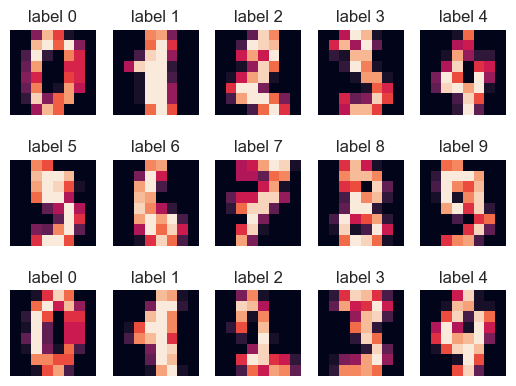

In [16]:
# A help function to display images with labels
def display_digits(imgs):
    h = 3
    w = 5
    fig, axes = plt.subplots(h, w)
    for i in range(h):
        for j in range(w):
            if imgs.shape[1] == 64:
                axes[i, j].imshow(imgs[i * w + j].reshape(8, 8))
            else:
                axes[i, j].imshow(imgs[i * w + j])
            axes[i, j].axis('off')
            axes[i, j].set_title(f'label {data_digit.target[i * w + j]}')
# Take a look at a few examples
display_digits(data_digit.images)

**PCA** finds uncorrelated orthogonal axes (principal components) in a high dimensional space (i.e., 64) to project the feature onto principal components.

## Question 3.1 (PCA and dimensionality deduction with Scikit-learn, 10 pts)

In this question, you may use the implementation of PCA from scikit-learn, as imported below. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Fit the model with feature X (**data_digit.data** for this dataset) and apply the dimensionality reduction on X, keep 2 components.

In [17]:
from sklearn.decomposition import PCA

################# Your answer for Question 3.1   #################
# PCA model that keeps the 2 components with the largest variance
pca = PCA(n_components=2)
# name the transformed (dimension reduced) feature as projected
# Fit PCA on the 64-pixel features and project them onto the 2 components
projected = pca.fit_transform(data_digit.data)
################# Complete the code above #################


# The code below checks whether the feature dimension 64 is reduced to 2.
print(data_digit.data.shape)
print(projected.shape)

(1797, 64)
(1797, 2)


With the reduced dimension of features, we can now visualize the projected/reduced features in a 2-dimension plot as below. There are hardly any overlaps between digit 0 and any other digits. While in the central area of the figure, features are not well separable.

<Figure size 1800x800 with 0 Axes>

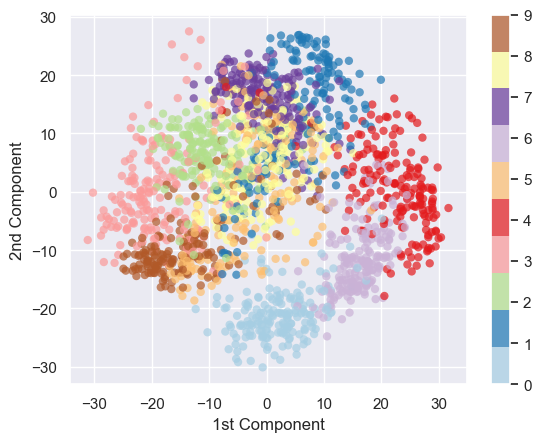

<Figure size 1800x800 with 0 Axes>

In [18]:
plt.scatter(projected[:, 0], projected[:, 1],
            c=data_digit.target, edgecolor='none', alpha=0.7,
            # plt.cm.get_cmap was removed in Matplotlib 3.9, so use plt.get_cmap
            cmap=plt.get_cmap('Paired', 10))
plt.xlabel('1st Component')
plt.ylabel('2nd Component')
plt.colorbar()
plt.figure(figsize=(18, 8))

## Question 3.2 (How many components do we need? 15 pts)

In practice, suppose you are given a high-dimension dataset, and you are interested in performing a dimension reduciton with PCA. How many conponents do we need? One method is to look at the distribution of the explained variance ratio w.r.t. each component.

In this question, you may use the function <code>explained_variance_ratio</code> in **pca** (with scikit-learn) to address this question. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Print the ratio of variance explained by each of the selected components;

Visualize with matplotlib or seaborn (x axis: $i-th$ component; y axis: the corresponding ratio of explained variance).

[0.1489 0.1362 0.1179 0.0841 0.0578 0.0492 0.0432 0.0366 0.0335 0.0308
 0.0237 0.0227 0.0182 0.0177 0.0147 0.0141 0.0132 0.0125 0.0102 0.0091
 0.0089 0.008  0.0077 0.0072 0.007  0.006  0.0058 0.0052 0.0049 0.0043
 0.0037 0.0035 0.0034 0.0033 0.0031 0.0029 0.0026 0.0023 0.0022 0.0021
 0.0019 0.0016 0.0015 0.0014 0.0012 0.0011 0.001  0.0008 0.0006 0.0004
 0.0002 0.0001 0.0001 0.0001 0.     0.     0.     0.     0.     0.
 0.     0.     0.     0.    ]
80% of variance needs 13 components
90% of variance needs 21 components
95% of variance needs 29 components


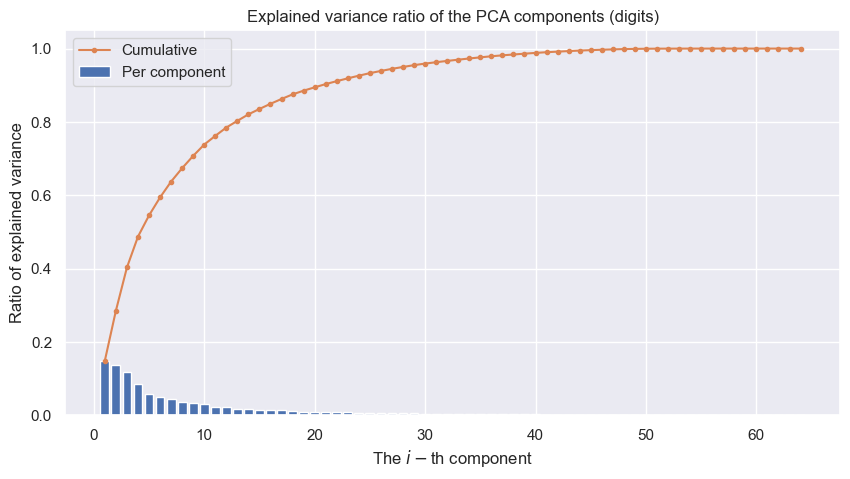

In [19]:
################# Your answer for Question 3.2   #################
# Fit PCA with all 64 components (default n_components = feature dimension)
pca_full = PCA().fit(data_digit.data)
# Ratio of the total variance explained by each component
ratios = pca_full.explained_variance_ratio_
print(np.array2string(ratios, precision=4, suppress_small=True))
# Cumulative explained variance after the first k components
cum_ratios = np.cumsum(ratios)
# First index where the cumulative ratio reaches the target, +1 to count components
for target in (0.80, 0.90, 0.95):
    k = np.searchsorted(cum_ratios, target) + 1
    print(f'{int(target * 100)}% of variance needs {k} components')

# Bar chart of each component's ratio, line for the cumulative ratio
components = np.arange(1, len(ratios) + 1)
plt.figure(figsize=(10, 5))
plt.bar(components, ratios, label='Per component')
plt.plot(components, cum_ratios, 'o-', color='C1', markersize=3, label='Cumulative')
plt.xlabel('The $i-$th component')
plt.ylabel('Ratio of explained variance')
plt.title('Explained variance ratio of the PCA components (digits)')
plt.legend()
################# Complete the code above #################

### How to obtain eigen values and vectors from sklearn PCA

- Eigen values -- <code>your-PCA-model\.explained\_variance\_</code>

- Eigen vectors -- <code>your-PCA-model.components_ </code>

### Eigen vectors (Eigen digits)

Text(0.5, 0.98, 'The eigen vector of each component')

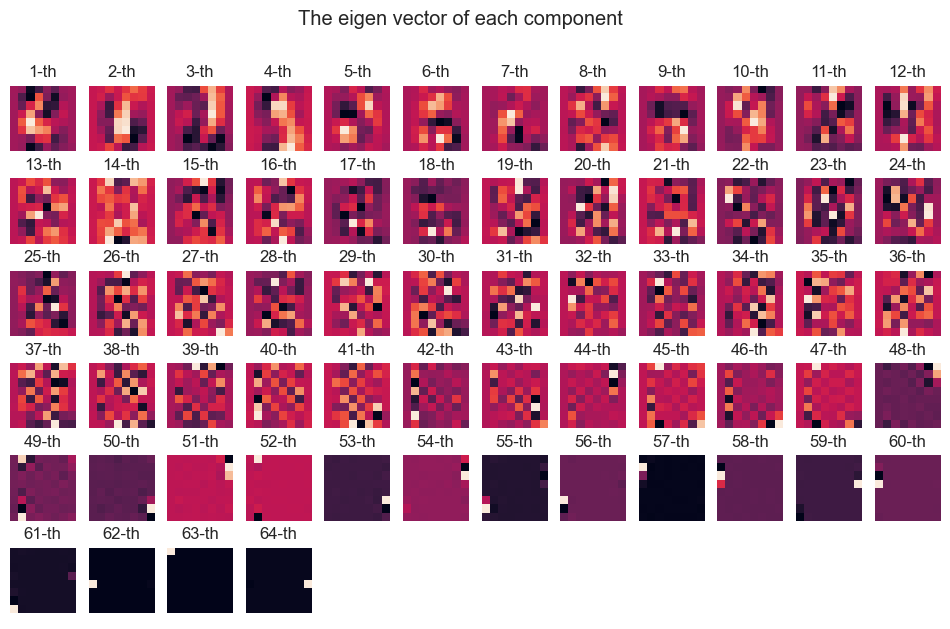

In [20]:
# Default # of components is the dimension of feature space 
pca = PCA()
pca.fit(data_digit.data)
h = 6
w = 12
fig, axes = plt.subplots(h, w)
fig.set_size_inches(12, 7)
for i in range(h):
    for j in range(w):
        idx = i * w + j
        if idx > 63:
            axes[i, j].axis('off')
        else:
            axes[i, j].imshow(pca.components_[idx].reshape(8, 8))
            axes[i, j].axis('off')
            axes[i, j].set_title(f'{idx + 1}-th')
fig.suptitle('The eigen vector of each component')

## Question 3.3 What are your observations from the visualized eigen vectors? (5 pts)

### Your solutions for Question 3.3:

Each image is one principal direction (eigenvector) in the 64-pixel space, shown as an 8×8 picture, ordered from the largest to the smallest explained variance.

- **First components (about 1–12): large, smooth, stroke-like patterns.** They consist of big connected bright and dark regions in the centre of the image that look like pieces of digit strokes (vertical bars, loops and curves). These are the main ways in which the digits differ from each other, so they carry most of the variance: the first component alone explains 14.9%, the first two 28.5%, the first three 40.3%, the first five 54.5% and the first ten 73.8%.
- **Later components (about 15–47): finer, high-frequency, checkerboard-like patterns.** Neighbouring pixels alternate between bright and dark. They describe small details of individual handwriting and pixel-level noise rather than the overall digit shape, and each one explains only a small fraction of the variance (below 1.5% from the 15th component on).
- **Last components (about 48–64): almost blank images with one or two bright pixels on the border.** The bright pixels are in the leftmost and rightmost columns and the corners. These border pixels barely vary because the digits are drawn in the middle of the image: 16 pixels, all in the first or last column or a top/bottom corner, have variance below 1, and 3 pixels, at (row, column) (0, 0), (4, 0) and (4, 7), have **zero variance** (`data_digit.data.var(axis=0) == 0`), i.e. they are always 0. The 62nd–64th components are exactly single-pixel images at these positions, and the last components explain essentially 0% of the variance.

**Connection to Question 3.2:** because the variance is concentrated in the first, smooth components, a few of them are enough to describe the digits: **13 components keep 80%** of the variance (80.3%), 21 keep 90% and **29 keep 95%**. The remaining 35 components, the high-frequency and border-pixel patterns, together hold less than 5% of the variance, so they can be dropped with little loss of information. This is what makes PCA useful for dimensionality reduction (and, as Question 3.4 shows, for removing noise).

### Feature reconstruction:

Suppose you only want to preserve $80\%$ variance after applying PCA for the dimension reduction, due to storage issues, etc. 

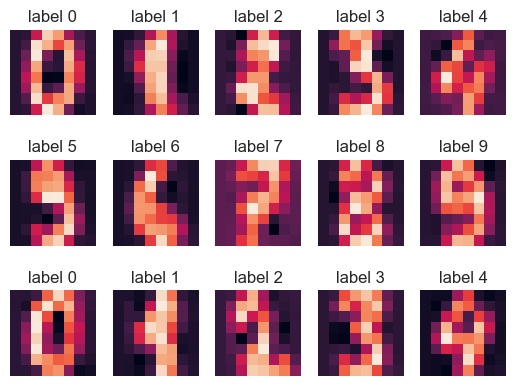

In [21]:
# Use pca from sklearn to fit on the feature space
pca_08 = PCA(0.8).fit(data_digit.data)

# Reconstruct 
lower_dimension = pca_08.fit_transform(data_digit.data)
reconstructed = pca_08.inverse_transform(lower_dimension)

# Display the reconstructed images (with a much lower dimension)
display_digits(reconstructed)

Assume now you are given only a set of perturbed images (with some random noise). As shown below, the figures become much more difficult to recognize.

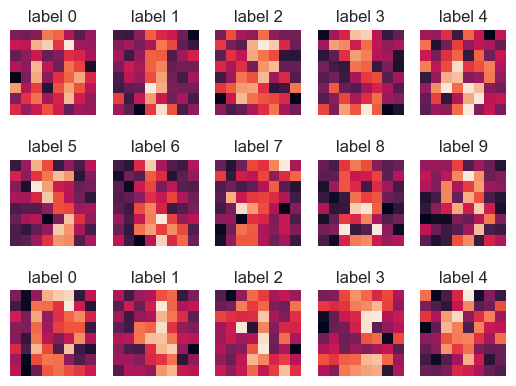

In [22]:
# Apply random noise on clean images
noisy_imgs = np.random.normal(data_digit.data, 5)
# Display the noisy images
display_digits(noisy_imgs)

## Question 3.4 Does PCA mitigate the random noise? (10 pts)

### Your tasks:

- Perform feature reconstruction on <code>noisy\_imgs</code> (preserving $80\%$ variance after applying PCA for the dimension reduction)

- Explain your understandings on why PCA reconstructs cleaner images.

Components kept: 40
MSE noisy vs clean:         24.89
MSE reconstructed vs clean: 17.41


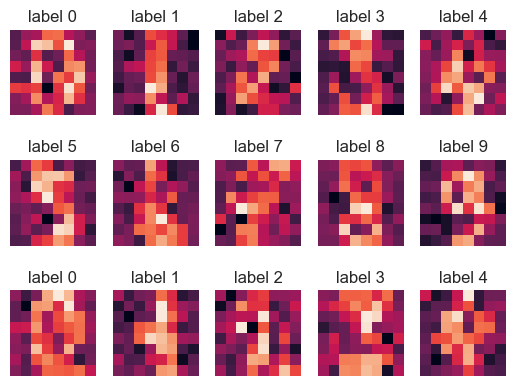

In [23]:
################# Your answer for Question 3.4   #################
# PCA that keeps the fewest components explaining 80% of the noisy images' variance
pca_noise = PCA(0.8).fit(noisy_imgs)
print('Components kept:', pca_noise.n_components_)

# name the reconstructed images from noisy images as 'reconstructed_noise'
# Project onto the kept components, then map back to the 64-pixel space
reconstructed_noise = pca_noise.inverse_transform(pca_noise.transform(noisy_imgs))
# Mean squared error to the clean images, before and after the PCA reconstruction
mse_noisy = metrics.mean_squared_error(data_digit.data, noisy_imgs)
mse_recon = metrics.mean_squared_error(data_digit.data, reconstructed_noise)
print(f'MSE noisy vs clean:         {mse_noisy:.2f}')
print(f'MSE reconstructed vs clean: {mse_recon:.2f}')
# Display the reconstructed images
display_digits(reconstructed_noise) 
################# Complete the code above #################

### Your written answers for Question 3.4:

*Note: the noise is random and unseeded, so the numbers below change slightly every time the notebook is run; across my runs the errors varied by about ±0.2 and the number of components between 40 and 41.*

**Yes, PCA partly removes the noise.** Keeping 80% of the variance of the noisy images uses **about 40 components** (40–41 in my runs). The mean squared error to the clean images drops from **about 25.0** for the noisy images (as expected for noise with standard deviation 5, since $5^2 = 25$) to **about 17.5** for the PCA reconstruction, i.e. roughly 30% less error. Visually, the reconstructed digits are somewhat smoother and easier to recognise (for example the rings of the 0s and the strokes of the 1s and 7s stand out more, and the border pixels are darker), although they are still clearly noisier than the clean images.

**Why PCA reconstructs cleaner images:**
- The structure of the digits lives in **a few directions**: as seen in Questions 3.2 and 3.3, 13 components already hold 80% of the variance of the clean images, and the pixels of a digit are strongly correlated with each other (strokes cover neighbouring pixels).
- The added noise is **independent for every pixel**, with the same variance in every direction, so it is spread evenly over **all 64 dimensions** and has no preferred direction.
- PCA keeps the directions with the largest variance. These are dominated by the digit signal, so projecting onto the top components and mapping back (`inverse_transform`) keeps most of the signal while **throwing away the noise that lies in the dropped directions**. With about 40 of 64 directions kept, roughly $24/64 \approx 37\%$ of the noise is removed, which matches the drop in error (expected remaining noise error $\approx 25 \times 40/64 \approx 15.6$, plus a little lost signal, gives the observed $\approx 17.5$).

**Limitation:** the noise is strong. A standard deviation of 5 on pixel values that range from 0 to 16 means the total noise variance ($64 \times 25 = 1600$) is larger than the total variance of the clean digits (about 1200), so noise makes up about 57% of the variance of the noisy images. To keep 80% of that variance, PCA must keep about 40 components instead of the 13 needed for the clean images, and many of those extra components mainly carry noise. As a result, a substantial part of the noise remains in the reconstruction. Keeping fewer components (for example a lower variance threshold, or the number chosen from the clean data) would remove more noise, at the cost of losing some detail of the digits.

# Acknowledgement of AI assistance

- I used an AI assistant (Claude, by Anthropic) to help write the code and the written answers in this notebook.
- I ran the notebook myself from top to bottom and checked that the outputs and the numbers in the written answers are correct.
- The full chat transcripts of my conversations with the AI assistant are submitted to Canvas together with this assignment.
- I also used the scikit-learn documentation (https://scikit-learn.org/stable/), in particular the pages for `train_test_split`, `LinearRegression`, `mean_squared_error` and `PCA`.